# Project III

In [1]:
%load_ext autoreload
%autoreload 2
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2
from scipy.stats import norm


import w8_estimation as est 
import w8_LinearModel as lm
import w8_probit as probit
import w8_logit as logit

In [2]:
dat = pd.read_csv('ppcs_cc.csv')

In [3]:
dat.sample(5)

,sblack,shisp,swhite,sother,smale,sage,sempl,sincome,spop,daytime,inctype_lin,omajblack,omajhisp,omajwhite,omajother,osplit,sbehavior,year,anyuseofforce_coded
2195,1,0,0,0,0,38,1,1,2,1,2,0,0,1,0,0,0,2011,0
2000,0,0,1,0,1,52,1,3,1,0,2,0,0,1,0,0,0,2011,0
2420,0,0,1,0,1,51,0,1,2,1,2,0,0,1,0,0,0,2011,0
2963,0,0,1,0,1,18,0,3,1,1,2,0,0,1,0,0,0,2011,0
2757,0,0,1,0,0,17,0,3,1,1,2,0,1,0,0,0,0,2011,0


In [4]:
dat.describe()

,sblack,shisp,swhite,sother,smale,sage,sempl,sincome,spop,daytime,inctype_lin,omajblack,omajhisp,omajwhite,omajother,osplit,sbehavior,year,anyuseofforce_coded
count,3799.000000,3799.000000,3799.000000,3799.000000,3799.000000,3799.000000,3799.000000,3799.000000,3799.000000,3799.000000,3799.000000,3799.000000,3799.000000,3799.000000,3799.000000,3799.0,3799.000000,3799.0,3799.000000
mean,0.110555,0.101606,0.739142,0.048697,0.529613,41.010003,0.695446,2.164780,1.362727,0.666491,1.958410,0.060805,0.023954,0.903659,0.011582,0.0,0.065017,2011.0,0.005001
std,0.313622,0.302169,0.439160,0.215262,0.499188,16.146916,0.460279,0.848262,0.765598,0.471529,0.199676,0.239005,0.152925,0.295097,0.107009,0.0,0.246589,0.0,0.070552
min,0.000000,0.000000,0.000000,0.000000,0.000000,16.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,2011.0,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,27.000000,0.000000,1.000000,1.000000,0.000000,2.000000,0.000000,0.000000,1.000000,0.000000,0.0,0.000000,2011.0,0.000000
50%,0.000000,0.000000,1.000000,0.000000,1.000000,40.000000,1.000000,2.000000,1.000000,1.000000,2.000000,0.000000,0.000000,1.000000,0.000000,0.0,0.000000,2011.0,0.000000
75%,0.000000,0.000000,1.000000,0.000000,1.000000,52.000000,1.000000,3.000000,1.000000,1.000000,2.000000,0.000000,0.000000,1.000000,0.000000,0.0,0.000000,2011.0,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,90.000000,1.000000,3.000000,4.000000,1.000000,2.000000,1.000000,1.000000,1.000000,1.000000,0.0,1.000000,2011.0,1.000000


dat[dat['anyuseofforce_coded'] == 1].describe()

In [5]:
df=dat.copy()

df.drop(columns=['osplit', 'year'], inplace=True) #no variance in these variables, so we drop them
df = pd.get_dummies(df, columns=['sincome', 'spop', 'inctype_lin'], dtype=int) #make dummy variables for categorical variables

#add age squared variable
df['sage_sq'] = df['sage']**2
df['omajnonwhite'] = 1 - df['omajwhite'] #create a variable for non-white officers
df['const'] = 1

#choose reference categories for categorical variables
df = df.drop(columns=['swhite', 'omajwhite', 'sincome_2', 'spop_2', 'inctype_lin_2', 'omajhisp', 'omajother', 'omajblack']) #drop reference categories

df.insert(0, 'const', df.pop('const'))
df.sample(5)

,const,sblack,shisp,sother,smale,sage,sempl,daytime,sbehavior,anyuseofforce_coded,sincome_1,sincome_3,spop_1,spop_3,spop_4,inctype_lin_1,sage_sq,omajnonwhite
235,1,0,0,0,0,38,0,1,0,0,0,1,1,0,0,0,1444,0
1076,1,0,0,0,1,26,1,0,1,0,0,1,0,0,1,0,676,0
2687,1,0,0,0,1,45,1,0,0,0,1,0,1,0,0,0,2025,0
3242,1,0,0,0,0,21,1,1,0,0,0,0,1,0,0,0,441,0
152,1,0,0,0,1,68,1,1,0,0,0,1,1,0,0,0,4624,0


In [6]:
# Create different data-frames for different models
x1 = ['const', 'sblack', 'shisp', 'sother']
x2 = x1 + ['sage', 'sage_sq', 'smale', 'sempl', 'sincome_1', 'sincome_3',
           'spop_1', 'spop_3', 'spop_4', 'inctype_lin_1']
x3 = x2 + ['daytime', 'omajnonwhite']
x4 = x3 + ['sbehavior']

# Final check
len(df.columns) == len(x4) + 1 # +1 for the dependent variable

True

In [7]:
#labels_x = list(df.columns)
#labels_x.remove('anyuseofforce_coded') #remove dependent variable from list of labels
labels_y = ['anyuseofforce_coded'] #dependent variable

# Convert to numpy arrays for estimation
y = df.anyuseofforce_coded.values
#x = df[labels_x].values

#K = x.shape[1] #number of independent variables
N = x.shape[0] #number of observations

print(x)

NameError: name 'x' is not defined

# LPM

In [ ]:
# MODELS
models = [x1, x2, x3, x4]
i = 0
LPM_models = [] # list for saving results
for model in models:
    i += 1
    x = df[model].values
    K_model = x.shape[1] #number of independent variables

    ols_results_model = lm.estimate(y=y, x=x, robust_se=True)
    ols_tab = lm.print_table((labels_y, model), ols_results_model, title='LPM')
    LPM_models.append(ols_tab)
    print(f'------Model {i}------')

LPM
Dependent variable: ['anyuseofforce_coded']

R2 = 0.003
sigma2 = nan
------Model 1------
LPM
Dependent variable: ['anyuseofforce_coded']

R2 = 0.018
sigma2 = nan
------Model 2------
LPM
Dependent variable: ['anyuseofforce_coded']

R2 = 0.019
sigma2 = nan
------Model 3------
LPM
Dependent variable: ['anyuseofforce_coded']

R2 = 0.034
sigma2 = nan
------Model 4------


# PROBIT

In [ ]:
models = [x1, x2, x3, x4]
i = 0
probit_models = [] # list for saving results
criterion_probit = []

for model in models:
    i += 1
    x = df[model].values
    K_model = x.shape[1] #number of independent variables
    N = x.shape[0]
    assert N == y.shape[0]  # Ensure that we haven't made any bad mistake

    theta0 = probit.starting_values(y=y, x=x)
    probit_results = est.estimate(probit.q, theta0, y=y, x=x, method='BFGS', cov_type='Sandwich') #Use sandwich covariance matrix because model likely not correctly specified
    q_fun = N*(-1)*probit_results['fun'] #Total sum of likelihood contributions.
    probit_tab = est.print_table((model), probit_results, title='PROBIT')
    probit_models.append(probit_tab)
    criterion_probit.append(q_fun)
    print(f'------Model {i}------')



Optimization terminated successfully.
         Current function value: 0.030440
         Iterations: 37
         Function evaluations: 195
         Gradient evaluations: 39
Optimizer succeeded after 37 iter. (195 func. evals.). Final criterion:  0.03044.
PROBIT
------Model 1------
Optimization terminated successfully.
         Current function value: 0.025411
         Iterations: 112
         Function evaluations: 1845
         Gradient evaluations: 123
Optimizer succeeded after 112 iter. (1845 func. evals.). Final criterion:  0.02541.
PROBIT
------Model 2------
Optimization terminated successfully.
         Current function value: 0.025088
         Iterations: 118
         Function evaluations: 2193
         Gradient evaluations: 129
Optimizer succeeded after 118 iter. (2193 func. evals.). Final criterion:  0.02509.
PROBIT
------Model 3------
Optimization terminated successfully.
         Current function value: 0.021863
         Iterations: 138
         Function evaluations: 2664
   

In [ ]:
probit_models

[         theta      se        t
 const  -2.7262  0.1100 -24.7932
 sblack  0.2759  0.2347   1.1754
 shisp   0.5703  0.1952   2.9224
 sother  0.1790  0.3644   0.4910,
                 theta      se       t
 const         -2.9199  0.7831 -3.7286
 sblack         0.0840  0.2546  0.3299
 shisp          0.3742  0.2112  1.7712
 sother         0.1098  0.3830  0.2868
 sage           0.0437  0.0411  1.0630
 sage_sq       -0.0008  0.0006 -1.3673
 smale          0.5119  0.2024  2.5284
 sempl         -0.5000  0.2133 -2.3438
 sincome_1     -0.0799  0.2226 -0.3591
 sincome_3      0.0694  0.1980  0.3506
 spop_1        -0.5402  0.2085 -2.5909
 spop_3        -0.2775  0.3876 -0.7159
 spop_4         0.0151  0.3342  0.0452
 inctype_lin_1  0.7635  0.2241  3.4066,
                 theta      se       t
 const         -2.8193  0.7798 -3.6156
 sblack         0.1298  0.2591  0.5010
 shisp          0.4131  0.2118  1.9508
 sother         0.0910  0.3776  0.2411
 sage           0.0447  0.0413  1.0812
 sage_sq      

# LOGIT

In [ ]:
models = [x1, x2, x3, x4]
i = 0
logit_models = [] # list for saving results
criterion_logit = []

for model in models:
    i += 1
    x = df[model].values
    K_model = x.shape[1] #number of independent variables
    N = x.shape[0]

    assert N == y.shape[0] # Ensure that we haven't made any bad mistake.

    theta0 = logit.starting_values(y=y, x=x)
    logit_results = est.estimate(logit.q, theta0, y=y, x=x, method='BFGS', cov_type='Sandwich') #Use sandwich covariance matrix because model likely not correctly specified
    q_fun = N*(-1)*logit_results['fun'] #Total sum of likelihood contributions.
    logit_tab = est.print_table((model), logit_results, title='LOGIT')
    logit_models.append(logit_tab)
    criterion_logit.append(q_fun)
    print(f'------Model {i}------')

Optimization terminated successfully.
         Current function value: 0.030440
         Iterations: 51
         Function evaluations: 265
         Gradient evaluations: 53
Optimizer succeeded after 51 iter. (265 func. evals.). Final criterion:  0.03044.
LOGIT
------Model 1------


/Users/nannawarming/Desktop/KA 2. Semester/Adv. Microeconometrics/Projects/Adv_microeconometrics_assignments/project 3/w8_logit.py:14: RuntimeWarning: overflow encountered in exp
  Gz = 1. / (1. + np.exp(-z))


Optimization terminated successfully.
         Current function value: 0.025566
         Iterations: 144
         Function evaluations: 2535
         Gradient evaluations: 169
Optimizer succeeded after 144 iter. (2535 func. evals.). Final criterion:  0.02557.
LOGIT
------Model 2------


/Users/nannawarming/Desktop/KA 2. Semester/Adv. Microeconometrics/Projects/Adv_microeconometrics_assignments/project 3/w8_logit.py:14: RuntimeWarning: overflow encountered in exp
  Gz = 1. / (1. + np.exp(-z))


Optimization terminated successfully.
         Current function value: 0.025289
         Iterations: 148
         Function evaluations: 2822
         Gradient evaluations: 166
Optimizer succeeded after 148 iter. (2822 func. evals.). Final criterion:  0.02529.
LOGIT
------Model 3------


/Users/nannawarming/Desktop/KA 2. Semester/Adv. Microeconometrics/Projects/Adv_microeconometrics_assignments/project 3/w8_logit.py:14: RuntimeWarning: overflow encountered in exp
  Gz = 1. / (1. + np.exp(-z))


Optimization terminated successfully.
         Current function value: 0.022139
         Iterations: 135
         Function evaluations: 2754
         Gradient evaluations: 153
Optimizer succeeded after 135 iter. (2754 func. evals.). Final criterion:  0.02214.
LOGIT
------Model 4------


---- LOGIT ----
Mean: 0.004796029154170277
Pred max: 0.4947501929289918
# above 50 percent: 0
---- PROBIT ----
Mean: 0.004546489120407346
Pred max: 0.3161471871425372
# above 50 percent: 0


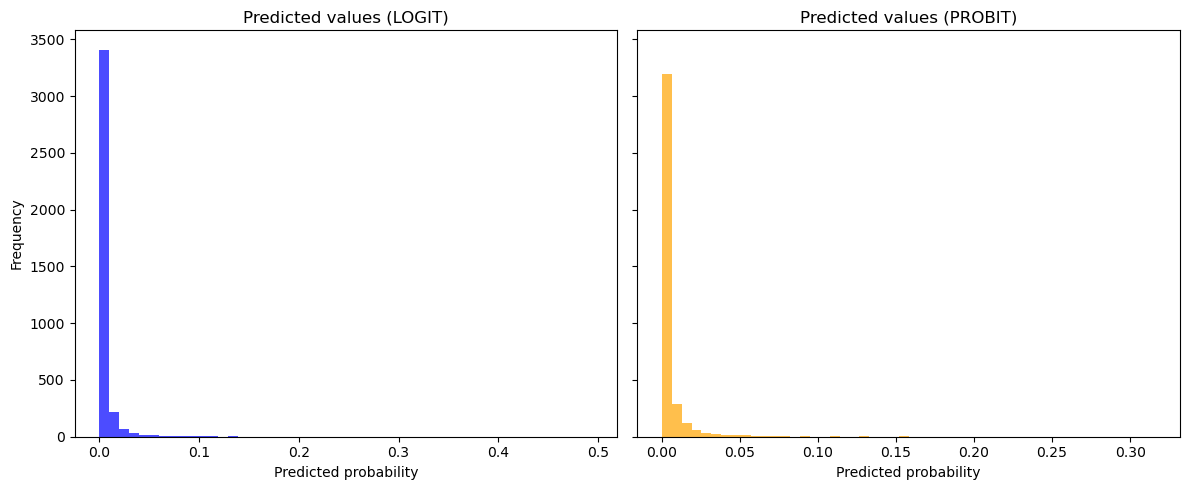

In [ ]:
## Distribution of predicted values for logit and probit model 3 (preffered?)
logit_model_3 = logit_models[2]
probit_model_3 = probit_models[2]
x = df[x3].values
pred_logit = logit.G(x@logit_model_3['theta'])
pred_probit = probit.G(x@probit_model_3['theta'])

fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

ax[0].hist(pred_logit, bins=50, alpha=0.7, color='blue')
ax[0].set_title('Predicted values (LOGIT)')
ax[0].set_xlabel('Predicted probability')
ax[0].set_ylabel('Frequency')

ax[1].hist(pred_probit, bins=50, alpha=0.7, color='orange')
ax[1].set_title('Predicted values (PROBIT)')
ax[1].set_xlabel('Predicted probability')

plt.tight_layout()

print('---- LOGIT ----')
print(f'Mean: {pred_logit.mean()}')
print(f'Pred max: {pred_logit.max()}')
print(f'# above 50 percent: {len(pred_logit[pred_logit>0.5])}')

print('---- PROBIT ----')
print(f'Mean: {pred_probit.mean()}')
print(f'Pred max: {pred_probit.max()}')
print(f'# above 50 percent: {len(pred_probit[pred_probit>0.5])}')

In [ ]:
### Parameter estimates for table 1

In [ ]:
# Printing out all model results. For probit and logit, std. errors are robust to misspecification
print('LPM')
for i,model in enumerate(models):
    print(f'----Model {i}----')
    print(LPM_models[i])

print('-----------------------')
print('-----------------------')
print('PROBIT')
for i,model in enumerate(models):
    print(f'----Model {i}----')
    print(probit_models[i])

print('-----------------------')
print('-----------------------')
print('LOGIT')
for i,model in enumerate(models):
    print(f'----Model {i}----')
    print(logit_models[i])

LPM
----Model 0----
         b_hat      se       t
const   0.0032  0.0011  3.0048
sblack  0.0039  0.0042  0.9275
shisp   0.0123  0.0064  1.9322
sother  0.0022  0.0055  0.4004
----Model 1----
                b_hat      se       t
const          0.0135  0.0098  1.3759
sblack         0.0019  0.0043  0.4450
shisp          0.0090  0.0060  1.5083
sother         0.0001  0.0057  0.0208
sage           0.0001  0.0003  0.2041
sage_sq       -0.0000  0.0000 -0.7378
smale          0.0048  0.0023  2.1054
sempl         -0.0065  0.0036 -1.7997
sincome_1     -0.0015  0.0033 -0.4416
sincome_3     -0.0002  0.0028 -0.0557
spop_1        -0.0080  0.0050 -1.6119
spop_3        -0.0045  0.0082 -0.5516
spop_4         0.0038  0.0105  0.3637
inctype_lin_1  0.0313  0.0150  2.0847
----Model 2----
                b_hat      se       t
const          0.0146  0.0103  1.4253
sblack         0.0024  0.0045  0.5365
shisp          0.0092  0.0060  1.5477
sother         0.0001  0.0057  0.0260
sage           0.0001  0.0003  0.

In [ ]:
## Likelihood for probit and logit
print('PROBIT')
for i,model in enumerate(models):
    print(f'----Model {i}----')
    print(criterion_probit[i])

print('-----------------------')
print('-----------------------')
print('LOGIT')
for i,model in enumerate(models):
    print(f'----Model {i}----')
    print(criterion_logit[i])

PROBIT
----Model 0----
-115.64202981855904
----Model 1----
-96.53481803715466
----Model 2----
-95.30996330792183
----Model 3----
-83.05802189296055
-----------------------
-----------------------
LOGIT
----Model 0----
-115.64206417553696
----Model 1----
-97.12336518906756
----Model 2----
-96.07414853952868
----Model 3----
-84.10628102951016


In [ ]:
## Likelihood ratio tests for nested models for probit and logit
alpha = 0.05

LR_test_probit = {}
LR_test_logit = {}

for i in range(len(models) - 1):
    freedom = len(models[i + 1]) - len(models[i])
    critical_value = chi2.ppf(1 - alpha, freedom)
    key = f'model{i + 1}_to_{i + 2}'

    for results, criterion in [
        (LR_test_probit, criterion_probit),
        (LR_test_logit, criterion_logit),
    ]:
        LR = -2 * (criterion[i] - criterion[i + 1])
        pval = chi2.sf(LR, freedom)

        results[key] = {
            'LR_statistic': LR,
            'Degree_freedom': freedom,
            'critical_value': critical_value,
            'degrees_of_freedom': freedom,
            'p_value': pval,
        }

        print(f'{key}: LR={LR:.4f}, critical value={critical_value:.4f}, p-value={pval:.4g}')
    print()


model1_to_2: LR=38.2144, critical value=18.3070, p-value=3.482e-05
model1_to_2: LR=37.0374, critical value=18.3070, p-value=5.576e-05

model2_to_3: LR=2.4497, critical value=5.9915, p-value=0.2938
model2_to_3: LR=2.0984, critical value=5.9915, p-value=0.3502

model3_to_4: LR=24.5039, critical value=3.8415, p-value=7.416e-07
model3_to_4: LR=23.9357, critical value=3.8415, p-value=9.961e-07



## VOGUE TEST

In [ ]:
# Estimated variance
N = y.shape[0]
x = df[x3].values #If preffered model changes, this should change as well
probit_likelihood = probit.loglikelihood(probit_models[2]['theta'], y=y, x=x) # If preffered model changes, this should change as well
logit_likelihood = logit.loglikelihood(logit_models[2]['theta'], y=y, x=x) # If preffered model changes, this should change as well
diff = (probit_likelihood-logit_likelihood).reshape(-1,1)
eta_sq = 1/N * (diff.T @ diff).item()

# Test-statistic
denom = (eta_sq**(1/2)) / (N**(1/2))
num = diff.mean()
VMS = num / denom

# Critical value and p-value
z_critical = norm.ppf(0.975)
p_val = 2 * (1-norm.cdf(abs(VMS)))

print('VMS test (probit v.s logit) of model 3 yields:')
print(f'VMS = {VMS:.3f}, Critical value = {z_critical:.2f}, P value = {p_val:.3}')
print(f'Both models are misspecified = {p_val>0.05}')
print(f'Total log-likelihood value of probit = {probit_likelihood.sum():.3f}, Total log-like of logit = {logit_likelihood.sum():.3f}')


VMS test (probit v.s logit) of model 3 yields:
VMS = 0.892, Critical value = 1.96, P value = 0.373
Both models are misspecified = True
Total log-likelihood value of probit = -95.481, Total log-like of logit = -96.101


# Partiel effects at the avarage (PEA)

In [ ]:
models = {"x1": x1, "x2": x2, "x3": x3, "x4": x4}
average_values = {}

for name, columns in models.items():
    average_values[name] = df[columns].to_numpy().mean(axis=0)

print(average_values["x1"])  # averages in the same order as the columns in x1
print(average_values["x2"]) 

counterfactual = {"sblack": 0, "shisp": 0, "sother": 0} #White

for name, columns in models.items():
    for variable, value in counterfactual.items():
        average_values[name][columns.index(variable)] = value

print(average_values["x1"])  # updated averages in the same order as the columns in x1
print(average_values["x2"]) 

[1.         0.11055541 0.10160569 0.04869703]
[1.00000000e+00 1.10555409e-01 1.01605686e-01 4.86970255e-02
 4.10100026e+01 1.94247460e+03 5.29613056e-01 6.95446170e-01
 2.90866017e-01 4.55646223e-01 7.68886549e-01 4.00105291e-02
 4.58015267e-02 4.15898921e-02]
[1. 0. 0. 0.]
[1.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 4.10100026e+01 1.94247460e+03 5.29613056e-01 6.95446170e-01
 2.90866017e-01 4.55646223e-01 7.68886549e-01 4.00105291e-02
 4.58015267e-02 4.15898921e-02]


In [ ]:
#manual try
values_white = average_values["x2"].copy()
values_black = average_values["x2"].copy()

sblack_index = columns.index("sblack")
values_black[sblack_index] = 1

values_white = values_white.reshape(1, -1)
values_black = values_black.reshape(1, -1)

probit_effect_black = probit.predict(probit_models[1]["theta"], values_black)[0]
probit_effect_white = probit.predict(probit_models[1]["theta"], values_white)[0]
diff = probit_effect_black - probit_effect_white

print(f'Probit effect for black: {probit_effect_black}')
print(f'Probit effect for white: {probit_effect_white}')
print(f'Difference: {diff}')


NameError: name 'probit_models' is not defined

In [ ]:
probit_models[1]["theta"]




NameError: name 'probit_models' is not defined

In [ ]:
bb = np.outer(b_pr,b_pr)
xx = np.outer(x_me, x_me)
I_K = np.eye(K)
gx0 = norm.pdf(x_me@b_pr)
gx2 = norm.pdf(x_me2@b_pr)

grad_c_pr = gx0*(np.eye(K) - bb @ xx)
grad_d_pr = gx2*x_me2 - gx0*x_me

In [ ]:
PEA_rows = []

for i, (name, columns) in enumerate(models.items()):
    values_white = average_values[name].copy()
    values_black = average_values[name].copy()

    sblack_index = columns.index("sblack")
    values_black[sblack_index] = 1

    # predict() expects a 2D array, even for one observation
    values_white = values_white.reshape(1, -1)
    values_black = values_black.reshape(1, -1)

    probit_effect = (
        probit.predict(probit_models[i]["theta"], values_black)[0]
        - probit.predict(probit_models[i]["theta"], values_white)[0]
    )
    logit_effect = (
        logit.predict(logit_models[i]["theta"], values_black)[0]
        - logit.predict(logit_models[i]["theta"], values_white)[0]
    )

    PEA_rows.append({
        "Model": name,
        "Probit effect": probit_effect,
        "Logit effect": logit_effect,
    })

effects_table = pd.DataFrame(PEA_rows).set_index("Model")
effects_table

,Probit effect,Logit effect
Model,,
x1,0.003933,0.003934
x2,0.000273,0.000666
x3,0.000411,0.000765
x4,0.000267,0.000247
